# Stage 3 — Covariate Acquisition (Minimal Set)

Acquire the two predictors required for the first end-to-end model:

- daily Mediterranean L4 reprocessed SST observations/analysis, used as a gap-free predictor;
- static ETOPO 2022 bathymetry.

The L3-only rule applies to the CHL target, not to predictors. Stage 8 later adds the validated surface salinity, currents/SSH, mixed-layer depth, KD490, and ERA5 wind groups; wave features remain deferred.


## 3.0 — Configuration

Same box and date window as Stage 1, copy-pasted for clarity.

In [1]:
from pathlib import Path

BOX = dict(
    minimum_longitude=12.0, maximum_longitude=15.5,
    minimum_latitude=35.5,  maximum_latitude=37.5,
)

START = "2021-01-01T00:00:00"
END   = "2023-12-31T00:00:00"

RAW_DIR = Path("data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

# L4 multi-year reprocessed SST observations/analysis for the Mediterranean.
# There is no L3 multi-year Med SST in this acquisition path, so we use L4 as a
# gap-free predictor. PLAN.md allows L4/model fields as inputs;
# the L3-only rule applies to the target (CHL), not predictors.
SST_DATASET_ID = "cmems_SST_MED_SST_L4_REP_OBSERVATIONS_010_021"
SST_DATASET_VERSION = "202411"
SST_DATASET_PART = "default"
SST_VARIABLES  = ["analysed_sst"]      # kelvin, ~5 km daily
SST_PATH       = RAW_DIR / "sst_malta_2021_2023.nc"

BATHY_PATH     = RAW_DIR / "bathy_malta.nc"
CHL_PATH       = RAW_DIR / "chl_malta_2021_2023.nc"

PROC_DIR = Path("data/processed")
DOMAIN_PATH = PROC_DIR / "chl_target_domain.nc"

assert CHL_PATH.exists(), "Missing CHL cube — run 01-Data-Acquisition first."

## 3.1 — Confirm the SST dataset ID

Use `cmems_SST_MED_SST_L4_REP_OBSERVATIONS_010_021`, a gap-free daily L4 reprocessed observation analysis for the Mediterranean. It is a predictor rather than the target. Resolve the pinned version and part before downloading so catalogue drift fails explicitly.


In [2]:
import copernicusmarine

catalogue = copernicusmarine.describe(
    dataset_id=SST_DATASET_ID,
    show_all_versions=True,
    raise_on_error=True,
)

print(f"OK — {SST_DATASET_ID} is reachable.")
print(f"Download will be pinned to version {SST_DATASET_VERSION}, "
      f"part {SST_DATASET_PART}.")

Fetching catalogue 1: 100%|██████████| 2/2 [00:00<00:00,  2.45it/s]

OK — cmems_SST_MED_SST_L4_REP_OBSERVATIONS_010_021 is reachable.
Download will be pinned to version 202411, part default.


## 3.2 — Download SST

Reuse an existing validated file while `FORCE = False`. Set `FORCE = True` only to deliberately replace it, then restore `False`. The request uses the surrounding source-grid cells required for interpolation onto the CHL grid.


In [3]:
# Set True only for an intentional replacement, then return it to False.
FORCE = False

if SST_PATH.exists() and not FORCE:
    size_mb = SST_PATH.stat().st_size / 1e6
    print(
        f"Skipping — {SST_PATH.name} exists ({size_mb:.1f} MB). "
        "Set FORCE=True to re-pull."
    )
else:
    copernicusmarine.subset(
        dataset_id=SST_DATASET_ID,
        dataset_version=SST_DATASET_VERSION,
        dataset_part=SST_DATASET_PART,
        variables=SST_VARIABLES,
        start_datetime=START,
        end_datetime=END,

        # Include the outer source-grid cells surrounding the CHL box.
        # Linear interpolation in Notebook 4 requires these cells.
        coordinates_selection_method="outside",

        output_filename=SST_PATH.name,
        output_directory=str(RAW_DIR),
        overwrite=FORCE,
        **BOX,
    )

    assert SST_PATH.exists(), f"Download did not create {SST_PATH}"

    print(
        f"Downloaded → {SST_PATH.resolve()} "
        f"({SST_PATH.stat().st_size / 1e6:.1f} MB)"
    )

INFO - 2026-08-20T11:31:39Z - Selected dataset version: "202411"
INFO - 2026-08-20T11:31:39Z - Selected dataset part: "default"
INFO - 2026-08-20T11:31:45Z - Total size of the download: 6.33 MB.


Downloaded → C:\GIT\mcast.pages.ai.v2\experiment\data\raw\sst_malta_2021_2023.nc (6.7 MB)


## 3.3 — Inspect SST

Confirm the variable, units, value range, exact daily time axis, ascending coordinates, and source-grid coverage. The validation gate requires the SST time axis to match CHL exactly and the SST grid to surround the CHL grid.


In [4]:
import xarray as xr
import numpy as np

sst_ds = xr.open_dataset(SST_PATH, chunks={"time": 50})
sst_var = SST_VARIABLES[0]
sst = sst_ds[sst_var]

print("Variable :", sst_var)
print("Dims     :", dict(sst.sizes))
print("Time     :", str(sst.time.values.min())[:10], "→", str(sst.time.values.max())[:10])
print("Lat range:", float(sst.latitude.min()),  "→", float(sst.latitude.max()))
print("Lon range:", float(sst.longitude.min()), "→", float(sst.longitude.max()))
print("Units    :", sst.attrs.get("units"))

# Sample a tiny slice to read out values without forcing the whole cube into memory
sample = sst.isel(time=slice(0, 30)).values
print(f"\nSample (first 30 days) — min {np.nanmin(sample):.2f}  "
      f"median {np.nanmedian(sample):.2f}  max {np.nanmax(sample):.2f}")

Variable : analysed_sst
Dims     : {'time': 1095, 'latitude': 42, 'longitude': 72}
Time     : 2021-01-01 → 2023-12-31
Lat range: 35.491878509521484 → 37.548343658447266
Lon range: 11.952619552612305 → 15.505882263183594
Units    : kelvin

Sample (first 30 days) — min 287.74  median 289.31  max 292.29


## 3.4 — Bathymetry from NOAA ETOPO 2022 (via ERDDAP)

We use ETOPO 2022 at 15 arc-seconds (~460 m, finer than our 1 km CHL grid). The download goes through NOAA PIFSC's **ERDDAP** service, which subsets server-side and returns a small netCDF — no auth, no manual tile selection, no global file download.

Key facts about the data:
- Variable name: **`z`** (elevation in metres)
- Coords: `latitude`, `longitude` (same convention as the CHL cube — no rename needed later)
- Sign: **negative = below sea level**, positive = land. We'll flip the sign to a positive 'depth' in Stage 4.

> If PIFSC ERDDAP is unreachable from your network, see the fallback cell below for downloading GEBCO 2024 manually.

In [5]:
import urllib.request

FORCE_BATHY = False

# ERDDAP .nc endpoint — subsets server-side to our exact box. ~1.6 MB.
ERDDAP_URL = (
    "https://oceanwatch.pifsc.noaa.gov/erddap/griddap/ETOPO_2022_v1_15s.nc"
    f"?z[({BOX['minimum_latitude']}):({BOX['maximum_latitude']})]"
    f"[({BOX['minimum_longitude']}):({BOX['maximum_longitude']})]"
)

if BATHY_PATH.exists() and not FORCE_BATHY:
    print(f"Skipping — {BATHY_PATH.name} exists "
          f"({BATHY_PATH.stat().st_size/1e6:.2f} MB). Set FORCE_BATHY=True to re-pull.")
else:
    print("Downloading ETOPO 2022 subset from PIFSC ERDDAP…")
    print(f"URL: {ERDDAP_URL}")
    urllib.request.urlretrieve(ERDDAP_URL, BATHY_PATH)
    print(f"Saved → {BATHY_PATH}  ({BATHY_PATH.stat().st_size/1e6:.2f} MB)")

Skipping — bathy_malta.nc exists (1.63 MB). Set FORCE_BATHY=True to re-pull.


In [6]:
bathy = xr.open_dataset(BATHY_PATH)
print(bathy)

# ETOPO ERDDAP gives us 'z' as the elevation variable. Stay defensive in case
# the user swapped to a GEBCO fallback below (which uses 'elevation').
elev_var = next(v for v in bathy.data_vars if v in ("z", "elevation", "bed_elevation"))
elev = bathy[elev_var]
print(f"\nElevation variable: {elev_var}")
print(f"Range  : {float(elev.min())} m to {float(elev.max())} m")
print(f"Median : {float(elev.median())} m   (should be a large negative number — open sea)")
print(f"Shape  : {dict(elev.sizes)}")

<xarray.Dataset> Size: 2MB
Dimensions:    (latitude: 481, longitude: 841)
Coordinates:
  * latitude   (latitude) float64 4kB 35.5 35.51 35.51 35.51 ... 37.49 37.5 37.5
  * longitude  (longitude) float64 7kB 12.0 12.01 12.01 ... 15.49 15.5 15.5
Data variables:
    z          (latitude, longitude) float32 2MB ...
Attributes: (12/38)
    cdm_data_type:                  Grid
    Conventions:                    CF-1.6, COARDS, ACDD-1.3
    creator_email:                  Barry.Eakins@noaa.gov
    creator_name:                   NOAA NCEI
    creator_type:                   institution
    creator_url:                    https://www.ngdc.noaa.gov/mgg/global/glob...
    ...                             ...
    standard_name_vocabulary:       CF Standard Name Table v70
    summary:                        ETOPO 2022, a global relief model with 15...
    sw_point_longitude:             0.02083333
    title:                          Bathymetry and Topography, NCEI ETOPO 202...
    Westernmost_East

### Fallback: GEBCO 2024 (manual)

If NOAA ERDDAP is unreachable from your network, download the GEBCO 2024 *sub-ice topo/bathy* netcdf from <https://www.gebco.net/data_and_products/gridded_bathymetry_data/> (free, no login). Drop the file at `data/raw/GEBCO_2024.nc`, then run:

```python
gebco = xr.open_dataset('data/raw/GEBCO_2024.nc')
bathy = gebco.sel(lon=slice(12.0, 15.5), lat=slice(35.5, 37.5))
bathy.to_netcdf('data/raw/bathy_malta.nc')
```

Variable will be called `elevation`; same sign convention as ETOPO.

---
## Validation Gate 3

The gate checks that:

1. SST and bathymetry files exist and contain the expected variables.
2. SST has the exact CHL daily time axis, ordered coordinates, plausible Kelvin values, and a grid that surrounds CHL for interpolation.
3. Bathymetry has ordered spatial coordinates, surrounds the CHL grid, and contains both sea depths and land elevations in plausible ranges.
4. Regridding the static bathymetry onto CHL leaves usable ocean coverage.

All checks must pass before feature construction.


In [7]:
import numpy as np
import pandas as pd
import xarray as xr

assert DOMAIN_PATH.exists(), (
    f"Missing {DOMAIN_PATH} — rerun Notebook 1 to create the "
    "observable target-domain mask."
)

chl_ds = xr.open_dataset(CHL_PATH, chunks={"time": 50})
sst_ds = xr.open_dataset(SST_PATH, chunks={"time": 50})
bathy_ds = xr.open_dataset(BATHY_PATH)

chl = chl_ds["CHL"]
sst = sst_ds[SST_VARIABLES[0]]
target_domain = xr.open_dataarray(DOMAIN_PATH).astype(bool).load()

elev_var = next(
    v for v in bathy_ds.data_vars
    if v in ("z", "elevation", "bed_elevation")
)
elev = bathy_ds[elev_var]

bathy_lat_name = "latitude" if "latitude" in elev.coords else "lat"
bathy_lon_name = "longitude" if "longitude" in elev.coords else "lon"
bathy_lat = elev[bathy_lat_name]
bathy_lon = elev[bathy_lon_name]

results = {}

# 1. Files and product identity
results["SST file present"] = (
    SST_PATH.exists() and SST_PATH.stat().st_size > 10_000
)
results["SST product is L4"] = (
    str(sst_ds.attrs.get("processing_level", "")).upper() == "L4"
)

# 2. Exact temporal alignment
chl_time = pd.DatetimeIndex(chl.time.values)
sst_time = pd.DatetimeIndex(sst.time.values)

results["CHL and SST time axes are identical"] = chl_time.equals(sst_time)
results["SST time is monotonic and unique"] = (
    sst_time.is_monotonic_increasing and sst_time.is_unique
)

sst_spatial_dims = ("latitude", "longitude")
sst_nonempty_by_day = sst.count(sst_spatial_dims)

results["every SST day contains ocean data"] = bool(
    (sst_nonempty_by_day > 0).all().compute().item()
)

# 3. Units and full-period physical range
sst_units = str(sst.attrs.get("units", "")).strip().lower()

if sst_units in {"kelvin", "k"}:
    sst_c = sst - 273.15
elif sst_units in {
    "celsius",
    "degree_celsius",
    "degrees_celsius",
    "degc",
    "°c",
}:
    sst_c = sst
else:
    raise RuntimeError(f"Unrecognised SST units: {sst_units!r}")

sst_min_c = float(sst_c.min(skipna=True).compute())
sst_max_c = float(sst_c.max(skipna=True).compute())

results["full SST range is physically plausible"] = (
    5.0 <= sst_min_c <= 20.0
    and 25.0 <= sst_max_c <= 35.0
)

# 4. Source grid must surround the CHL grid
results["SST grid surrounds the CHL grid"] = (
    float(sst.longitude.min()) <= float(chl.longitude.min())
    and float(sst.longitude.max()) >= float(chl.longitude.max())
    and float(sst.latitude.min()) <= float(chl.latitude.min())
    and float(sst.latitude.max()) >= float(chl.latitude.max())
)

# Test the exact spatial operation that Notebook 4 will perform.
sst_on_chl = sst.interp(
    latitude=chl.latitude,
    longitude=chl.longitude,
)

sst_valid_every_day = sst_on_chl.notnull().all("time").compute()

n_domain = int(target_domain.sum())
n_domain_with_sst = int(
    (target_domain & sst_valid_every_day).sum()
)
sst_domain_coverage = n_domain_with_sst / n_domain

# Some coastal CHL pixels may remain outside the coarser SST ocean mask.
# Those are legitimate missing predictor values and XGBoost can retain them.
results["SST covers at least 99% of the CHL domain"] = (
    sst_domain_coverage >= 0.99
)

# 5. Bathymetry checks
results["bathymetry is finite"] = bool(
    elev.notnull().all().compute().item()
)

results["bathymetry surrounds the CHL grid"] = (
    float(bathy_lon.min()) <= float(chl.longitude.min())
    and float(bathy_lon.max()) >= float(chl.longitude.max())
    and float(bathy_lat.min()) <= float(chl.latitude.min())
    and float(bathy_lat.max()) >= float(chl.latitude.max())
)

elev_min = float(elev.min())
elev_max = float(elev.max())

results["bathymetry contains ocean and land"] = (
    elev_min < -50 and elev_max > 0
)

# 6. Coordinate orientation
def strictly_ascending(coord):
    return bool(np.all(np.diff(np.asarray(coord)) > 0))

results["all latitude axes are ascending"] = all([
    strictly_ascending(chl.latitude.values),
    strictly_ascending(sst.latitude.values),
    strictly_ascending(bathy_lat.values),
])

results["all longitude axes are ascending"] = all([
    strictly_ascending(chl.longitude.values),
    strictly_ascending(sst.longitude.values),
    strictly_ascending(bathy_lon.values),
])

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print()
print(f"CHL/SST dates              : {chl_time[0].date()} → {chl_time[-1].date()}")
print(f"SST range                  : {sst_min_c:.2f} → {sst_max_c:.2f} °C")
print(f"CHL-domain pixels          : {n_domain:,}")
print(f"Pixels with daily SST      : {n_domain_with_sst:,}")
print(f"SST target-domain coverage : {sst_domain_coverage * 100:.2f}%")
print(f"Bathymetry range           : {elev_min:.0f} → {elev_max:.0f} m")

failed = [name for name, ok in results.items() if not ok]

if failed:
    raise RuntimeError(
        "Validation Gate 3 failed:\n- "
        + "\n- ".join(failed)
    )

print("\nGate 3 PASSED — proceed to 04-Build-Supervised.")

PASS  SST file present
PASS  SST product is L4
PASS  CHL and SST time axes are identical
PASS  SST time is monotonic and unique
PASS  every SST day contains ocean data
PASS  full SST range is physically plausible
PASS  SST grid surrounds the CHL grid
PASS  SST covers at least 99% of the CHL domain
PASS  bathymetry is finite
PASS  bathymetry surrounds the CHL grid
PASS  bathymetry contains ocean and land
PASS  all latitude axes are ascending
PASS  all longitude axes are ascending

CHL/SST dates              : 2021-01-01 → 2023-12-31
SST range                  : 11.59 → 30.93 °C
CHL-domain pixels          : 46,158
Pixels with daily SST      : 45,780
SST target-domain coverage : 99.18%
Bathymetry range           : -3060 → 971 m

Gate 3 PASSED — proceed to 04-Build-Supervised.


## 3.5 — Visual sanity (optional)

Plot a single SST day and the bathymetry. SST should show the seasonal warm pool offshore and a cooler coastal band; bathy should show the Sicilian shelf shallowing toward Cape Passero (NE corner) and the deep Strait of Sicily basin to the south.

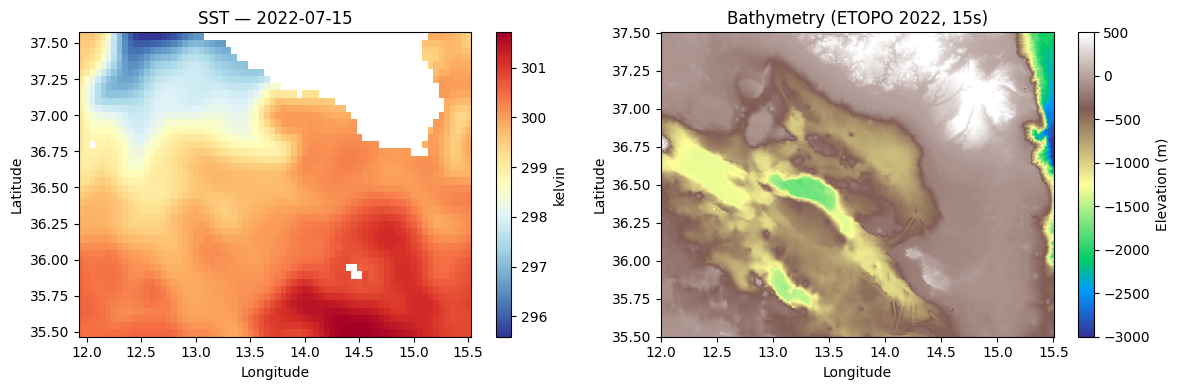

In [8]:
import matplotlib.pyplot as plt

FIG_DIR = Path("figs"); FIG_DIR.mkdir(exist_ok=True)
sst_day = sst.sel(time="2022-07-15", method="nearest")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

im0 = axes[0].pcolormesh(sst_day.longitude, sst_day.latitude, sst_day,
                         shading="auto", cmap="RdYlBu_r")
axes[0].set_title(f"SST — {str(sst_day.time.values)[:10]}")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
plt.colorbar(im0, ax=axes[0], label=sst.attrs.get("units", ""))

im1 = axes[1].pcolormesh(bathy_lon, bathy_lat, elev,
                         shading="auto", cmap="terrain", vmin=-3000, vmax=500)
axes[1].set_title("Bathymetry (ETOPO 2022, 15s)")
axes[1].set_xlabel("Longitude"); axes[1].set_ylabel("Latitude")
plt.colorbar(im1, ax=axes[1], label="Elevation (m)")

plt.tight_layout()
plt.savefig(FIG_DIR / "03_sst_and_bathy.png", dpi=150)
plt.show()

---
## Predictor roster for Stage 8

The validated Stage 8 acquisition adds these groups:

| Group | Variables used downstream |
|---|---|
| Surface hydrography | salinity |
| Circulation | eastward/northward current, current speed, SSH |
| Vertical structure | mixed-layer depth |
| Optics | KD490 |
| Atmosphere | ERA5 10 m wind components and derived wind diagnostics |

Waves and other experimental products are not part of the current 32-feature v2 model. They require a separate catalogue, coverage, and ablation study before inclusion.


---
## Next: `04-Build-Supervised.ipynb`

Turns the three cubes (CHL, SST, bathy) into a tidy `(features at t) → (target at t+h)` table for h ∈ {1..7}. This is where most silent bugs are born — Stage 4 includes a leakage assert that catches them.